<a href="https://colab.research.google.com/github/CarlosFranciscoM-Urzua/EJERCICIOS_PLN_COLAB/blob/main/TF_IDF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#PRÁCTICA TF-IDF

Carlos Francisco Montoya Urzúa

Paso 1. Calcular TF

In [1]:
frecuencia = 2
total_palabras = 10
tf = frecuencia / total_palabras
print("Frecuencia del término:", frecuencia)
print("Total de palabras:", total_palabras)
print("TF =", tf)

Frecuencia del término: 2
Total de palabras: 10
TF = 0.2


Paso 2. Calcular IDF

In [2]:
import math
N = 4
df = 1
idf = math.log(N / df)
print("Número de documentos:", N)
print("Documentos que contienen modelo:", df)
print("IDF =", round(idf, 4))


Número de documentos: 4
Documentos que contienen modelo: 1
IDF = 1.3863


Paso 3. Calcular TF-IDF

In [3]:
tf_idf = tf * idf
print("TF =", round(tf, 4))
print("IDF =", round(idf, 4))
print("TF-IDF =", round(tf_idf, 4))

TF = 0.2
IDF = 1.3863
TF-IDF = 0.2773


## 5.	Comparación entre «modelo» y «el»

In [4]:
import math # Palabra modelo
tf_modelo = 2 / 10
idf_modelo = math.log(4 / 1)
tfidf_modelo = tf_modelo * idf_modelo # Palabra el

tf_el = 3 / 10
idf_el = math.log(4 / 4)
tfidf_el = tf_el * idf_el
print("TF-IDF modelo:", round(tfidf_modelo, 4))
print("TF-IDF el:", round(tfidf_el, 4))

TF-IDF modelo: 0.2773
TF-IDF el: 0.0


## 6. Matriz TF-IDF con Scikit-learn

Paso 5. Importar bibliotecas y crear el corpus

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

documentos = [
    "modelo modelo datos inteligencia artificial",
    "inteligencia artificial analiza datos",
    "algoritmos procesan datos",
    "aprendizaje automatico utiliza algoritmos" ]

for i, documento in enumerate(documentos):
    print(f"Documento {i+1}: {documento}")


Documento 1: modelo modelo datos inteligencia artificial
Documento 2: inteligencia artificial analiza datos
Documento 3: algoritmos procesan datos
Documento 4: aprendizaje automatico utiliza algoritmos


Paso 6. Vectorizar los documentos

In [6]:
vectorizador = TfidfVectorizer()
matriz_tfidf = vectorizador.fit_transform(documentos)
print("Matriz TF-IDF generada correctamente")

Matriz TF-IDF generada correctamente


Paso 7. Convertir a tabla e interpretar

In [7]:
palabras = vectorizador.get_feature_names_out()
df_tfidf = pd.DataFrame(
    matriz_tfidf.toarray(),
    columns=palabras,
    index=["D1", "D2", "D3", "D4"]
)

display(df_tfidf.round(4))


,algoritmos,analiza,aprendizaje,artificial,automatico,datos,inteligencia,modelo,procesan,utiliza
D1,0.0000,0.0000,0.0000,0.3317,0.0000,0.2685,0.3317,0.8414,0.000,0.0000
D2,0.0000,0.6142,0.0000,0.4843,0.0000,0.3921,0.4843,0.0000,0.000,0.0000
D3,0.5535,0.0000,0.0000,0.0000,0.0000,0.4481,0.0000,0.0000,0.702,0.0000
D4,0.4143,0.0000,0.5255,0.0000,0.5255,0.0000,0.0000,0.0000,0.000,0.5255


## 7.	Construir una matriz con la fórmula manual

In [8]:
import math
import pandas as pd
from collections import Counter

documentos = [
    "modelo modelo datos inteligencia artificial",
    "inteligencia artificial analiza datos",
    "algoritmos procesan datos",
    "aprendizaje automatico utiliza algoritmos"
]

tokens = [
    documento.split() for documento in documentos
]
N = len(documentos)
vocabulario = sorted(set(
    palabra for documento in tokens for palabra in documento
))
resultados = []
for documento in tokens:
    frecuencias = Counter(documento)
    total = len(documento)
    fila = {}
    for palabra in vocabulario:
        tf = frecuencias[palabra] / total
        df = sum(palabra in doc for doc in tokens)
        idf = math.log(N / df)
        fila[palabra] = tf * idf
    resultados.append(fila)

tabla = pd.DataFrame(
    resultados,
    index=["D1", "D2", "D3", "D4"]
)
display(tabla.round(4))


,algoritmos,analiza,aprendizaje,artificial,automatico,datos,inteligencia,modelo,procesan,utiliza
D1,0.0000,0.0000,0.0000,0.1386,0.0000,0.0575,0.1386,0.5545,0.0000,0.0000
D2,0.0000,0.3466,0.0000,0.1733,0.0000,0.0719,0.1733,0.0000,0.0000,0.0000
D3,0.2310,0.0000,0.0000,0.0000,0.0000,0.0959,0.0000,0.0000,0.4621,0.0000
D4,0.1733,0.0000,0.3466,0.0000,0.3466,0.0000,0.0000,0.0000,0.0000,0.3466


/tmp/ipykernel_2912/679903421.py:33: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


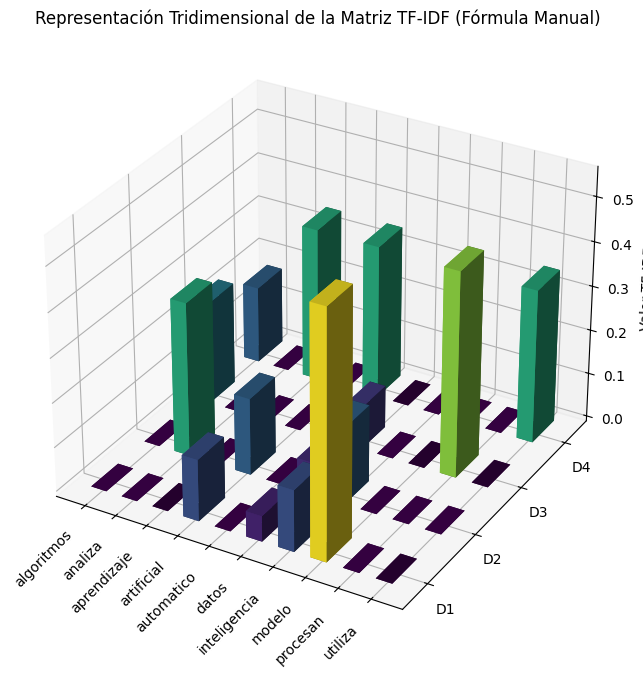

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Obtener las dimensiones de la tabla
docs = tabla.index
palabras = tabla.columns

_x = np.arange(len(palabras))
_y = np.arange(len(docs))
_xx, _yy = np.meshgrid(_x, _y)
x, y = _xx.ravel(), _yy.ravel()

top = tabla.values.ravel()
bottom = np.zeros_like(top)
width = depth = 0.5

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Usar un mapa de colores para representar la intensidad de TF-IDF
colores = plt.cm.viridis(top / max(top) if max(top) > 0 else top)

ax.bar3d(x, y, bottom, width, depth, top, color=colores, shade=True)

ax.set_xticks(_x + width/2)
ax.set_xticklabels(palabras, rotation=45, ha='right')
ax.set_yticks(_y + depth/2)
ax.set_yticklabels(docs)
ax.set_zlabel('Valor TF-IDF')
ax.set_title('Representación Tridimensional de la Matriz TF-IDF (Fórmula Manual)')

plt.tight_layout()
plt.show()

/tmp/ipykernel_2912/3644631075.py:32: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


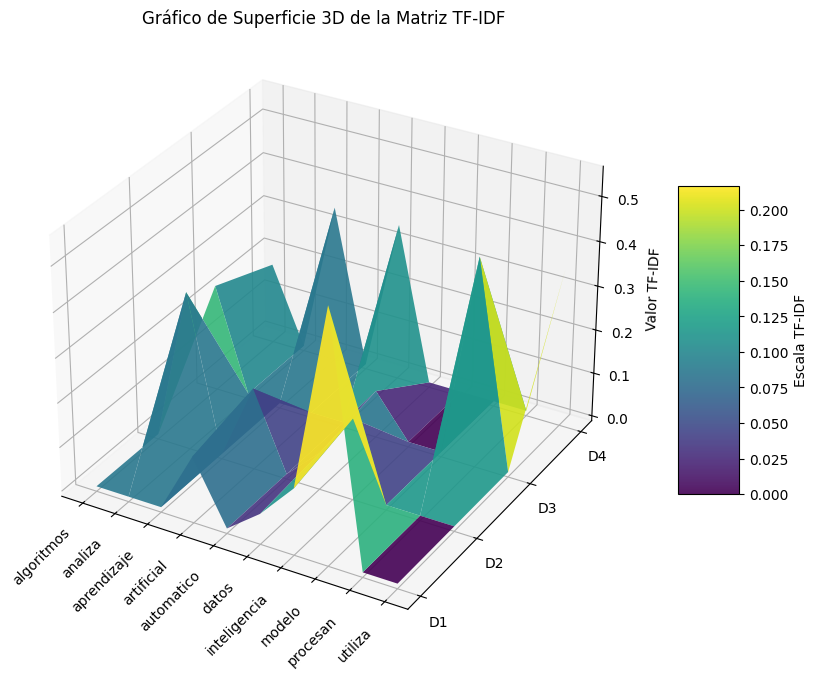

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Obtener las dimensiones de la tabla
docs = tabla.index
palabras = tabla.columns

# Crear coordenadas numéricas para los ejes
x_coords = np.arange(len(palabras))
y_coords = np.arange(len(docs))
X, Y = np.meshgrid(x_coords, y_coords)
Z = tabla.values

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Graficar la superficie utilizando un mapa de color
surf = ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.9)

# Configurar las etiquetas y los límites de los ejes
ax.set_xticks(x_coords)
ax.set_xticklabels(palabras, rotation=45, ha='right')
ax.set_yticks(y_coords)
ax.set_yticklabels(docs)
ax.set_zlabel('Valor TF-IDF')
ax.set_title('Gráfico de Superficie 3D de la Matriz TF-IDF')

# Añadir una barra de color para la escala
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5, label='Escala TF-IDF')

plt.tight_layout()
plt.show()

# 8.	Actividades para el estudiante

**Actividad 1. Cambiar la frecuencia**
Modificar la frecuencia de «modelo» a cuatro apariciones en un documento de diez palabras. Calcular TF, IDF y TF-IDF. Pregunta: ¿qué cambia al aumentar la frecuencia del término?


In [11]:
frecuencia = 4
total_palabras = 10
tf_modelo = frecuencia / total_palabras

print("Frecuencia del término:", frecuencia)
print("Total de palabras:", total_palabras)
print("TF =", tf_modelo)

idf_modelo = math.log(4 / 1)
print("IDF = ", idf)
tfidf_modelo = tf_modelo * idf_modelo
print("TF-IDF = ", tfidf_modelo)

Frecuencia del término: 4
Total de palabras: 10
TF = 0.4
IDF =  1.3862943611198906
TF-IDF =  0.5545177444479562


Al aumentar las veces que aparece una palabra en un documento, cambia el TF y el TF-IDF.

**Actividad 2. Cambiar el corpus**

Suponga N = 8,

df(«modelo») = 2 y

frecuencia = 2

en un documento de diez palabras.

Calcule TF-IDF.

Pregunta: ¿qué sucede con IDF cuando N y df aumentan proporcionalmente?


In [12]:
N = 8
frecuencia = 2
doc_f_modelo = 2
total_palabras = 10

tf_modelo = frecuencia / total_palabras
idf = math.log(N / doc_f_modelo)
tfidf_modelo = tf_modelo * idf

print("TF =", tf_modelo)
print("IDF = ", idf)
print("TF-IDF = ", tfidf_modelo)

TF = 0.2
IDF =  1.3862943611198906
TF-IDF =  0.2772588722239781


Cuando N y df aumentan proporcionalmente, al ser divididos, el IDF queda igual.

**Actividad 3. Encontrar los términos más importantes**

In [13]:
for documento in df_tfidf.index:
    print("\n", documento)
    importantes = df_tfidf.loc[documento].sort_values(         ascending=False     )
    print(importantes.head(3))



 D1
modelo          0.841362
artificial      0.331670
inteligencia    0.331670
Name: D1, dtype: float64

 D2
analiza         0.614226
artificial      0.484263
inteligencia    0.484263
Name: D2, dtype: float64

 D3
procesan      0.702035
algoritmos    0.553492
datos         0.448100
Name: D3, dtype: float64

 D4
automatico     0.525473
aprendizaje    0.525473
utiliza        0.525473
Name: D4, dtype: float64


Las palabras identificadas como mas importantes si representan su contenido

Se podrian obtener las siguientes palabras como mas caracteristicas del corpus:
* modelo
* procesan
* algoritmos

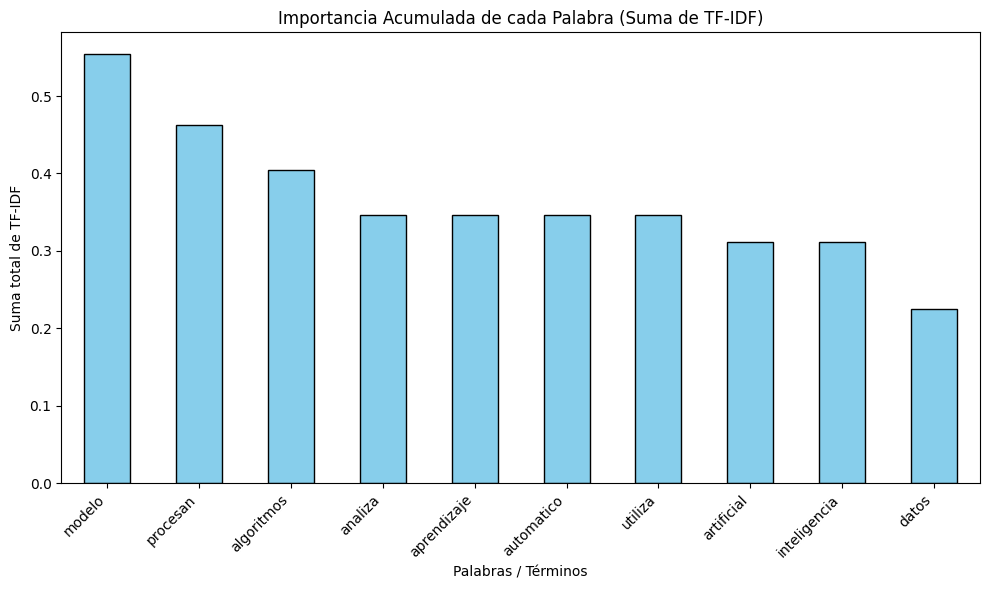

In [14]:
import matplotlib.pyplot as plt

# Sumar los valores de cada columna (palabra)
suma_palabras = tabla.sum().sort_values(ascending=False)

# Crear el gráfico de barras 2D
fig, ax = plt.subplots(figsize=(10, 6))
suma_palabras.plot(kind='bar', color='skyblue', edgecolor='black', ax=ax)

ax.set_title('Importancia Acumulada de cada Palabra (Suma de TF-IDF)')
ax.set_xlabel('Palabras / Términos')
ax.set_ylabel('Suma total de TF-IDF')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

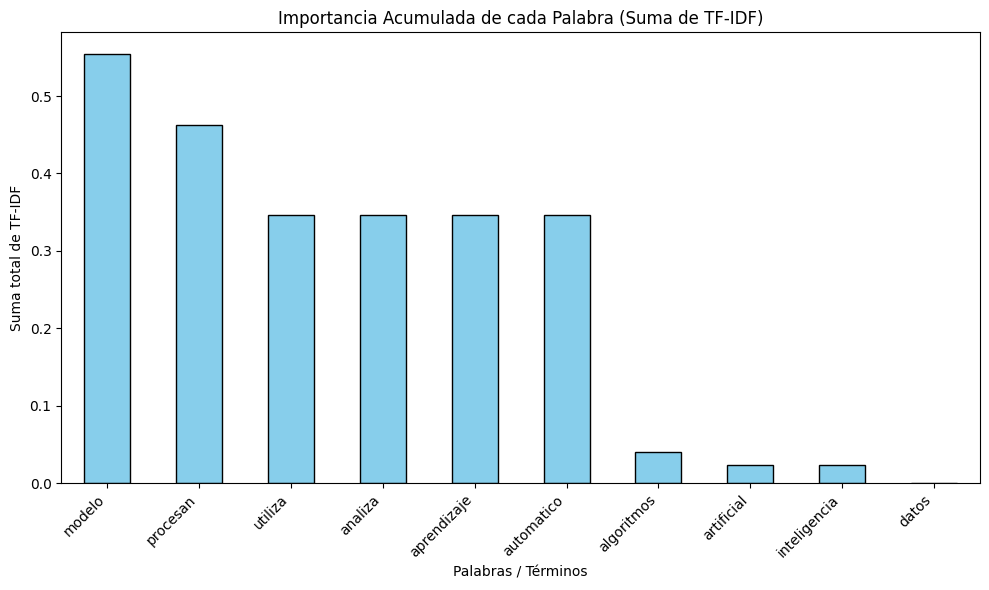

In [17]:
import matplotlib.pyplot as plt

# Sumar los valores de cada columna (palabra)
suma_palabras = tabla.replace(0,1).prod().sort_values(ascending=False)

# Crear el gráfico de barras 2D
fig, ax = plt.subplots(figsize=(10, 6))
suma_palabras.plot(kind='bar', color='skyblue', edgecolor='black', ax=ax)

ax.set_title('Importancia de cada Palabra (Producto de TF-IDF)')
ax.set_xlabel('Palabras / Términos')
ax.set_ylabel('Suma total de TF-IDF')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 9.	Cuestionario de reflexión

1.	**¿Qué diferencia existe entre TF e IDF?**

TF es la frecuencia relativa en cada documento. Mide la importancia de un término de manera local (frecuencia interna en un único documento).

IDF es la cantidad de documentos por cada vez que aparecen. Es una métrica global que evalúa qué tan común o rara es una palabra en la totalidad de la colección (corpus).

TF crece con la repetición; IDF decrece con la popularidad.


2.	**¿Por qué TF-IDF utiliza información de todos los documentos?**

Porque TF utiliza informacion de un documento a la vez, y IDF de todos los documentos.

Al mirar todos los documentos, el algoritmo penaliza de forma inteligente aquellas palabras que no tienen poder de discriminación semántica.

3.	**¿Qué sucede cuando una palabra aparece en todos los documentos?**

Esa palabra tendra un IDF de 0.

Matemáticamente, si $df = N$, entonces $\frac{N}{df} = 1$. Dado que $\log(1) = 0$, el $IDF = 0$, lo que anula completamente el valor final de TF-IDF para esa palabra en todos los textos (por ejemplo, artículos, conjunciones o palabras sumamente genéricas del dominio).

4.	**¿Por qué una palabra poco frecuente puede obtener un IDF alto?**

Porque una palabra poco frecuente aparece una vez cada varios documentos, haciendo que la división N/df sea más grande.

5.	**¿Qué diferencia existe entre una matriz BoW y una matriz TF-IDF?**

Solo cuenta cuántas veces aparece una palabra, mientras que TF-IDF ajusta ese conteo dándole más peso a las palabras únicas o relevantes y menos peso a las palabras muy comunes.

**BoW** es una representación de conteo plano que sufre del sesgo de frecuencia (las palabras más comunes dominan el vector sin importar si son informativas). **TF-IDF** actúa como un filtro de relevancia que balancea la frecuencia local con la exclusividad global.

6.	**¿Para qué se utiliza TfidfVectorizer?**

Para generar la matriz TF-IDF de forma automática.

Automatiza el flujo completo de Procesamiento de Lenguaje Natural (PLN): realiza la tokenización (separar en palabras), el filtrado opcional de stop words (palabras vacías), el cálculo de TF e IDF, y aplica la normalización vectorial (usualmente norma L2) para que la longitud del texto no sesgue los resultados.

7.	**¿Qué representa cada fila de una matriz TF-IDF?**

Cada fila representa los valores TF-IDF de cada palabra dentro de un documento. Dando así información de la relevancia de cada palabra en un documento.

Cada fila es el vector numérico (en un espacio multidimensional) de un documento. La posición de cada celda mapea la relevancia de un token específico. Estos vectores permiten calcular numéricamente la similitud (por ejemplo, similitud de coseno) entre documentos o consultas de búsqueda.


8.	**¿Por qué los resultados de Scikit-learn pueden diferir del cálculo manual?**

Por la diferencia entre utilizar logaritmo natural y logaritmo en base 10.

Además de la base del logaritmo (Scikit-learn usa el logaritmo natural), la biblioteca añade un suavizado por defecto (`smooth_idf=True`) que suma $1$ tanto al numerador como al denominador de la fórmula: $\log(\frac{1 + N}{1 + df}) + 1$. Esto evita divisiones por cero y previene que términos con $df=N$ se eliminen por completo de la matriz, además de aplicar normalización L2 a los vectores resultantes.

9.	**¿En qué aplicaciones de PLN podría utilizarse TF-IDF?**

* Análisis de sentimientos
* Es la base de los motores de búsqueda (recuperación de información)
sistemas de recomendación de artículos por contenido
* Clasificación de texto (detección de Spam)
* Agrupación (clustering) de documentos temáticos y en la extracción automática de palabras clave.

10.	**¿Qué ventajas tiene TF-IDF frente a usar solo la frecuencia de palabras?**
* Permite ver que palabras son más importantes o significativas en un corpus completo.

* Elimina el ruido de fondo del idioma.

* Permite que el análisis posterior de Machine Learning se enfoque en los términos que realmente aportan valor semántico diferencial, mejorando significativamente la precisión de cualquier modelo predictivo.